## 1. Hugging Face Login

#### This imports the token from Kaggle Secrets, so make sure the secret is set correctly before running the code.

In [1]:
import os
from huggingface_hub import login
from kaggle_secrets import UserSecretsClient

user_secrets = UserSecretsClient()
HF_TOKEN = user_secrets.get_secret("HF_TOKEN")
os.environ["HF_TOKEN"] = HF_TOKEN
login(token=HF_TOKEN)

print("Hugging Face login successful.")

Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.


Hugging Face login successful.


## 2. Check GPU

In [2]:
import torch

print("CUDA available:", torch.cuda.is_available())
print("GPU count:", torch.cuda.device_count())
for i in range(torch.cuda.device_count()):
    print(f"GPU {i}:", torch.cuda.get_device_name(i))


def get_device():
    """
      Return the computing device used in the current session.
    """
    return torch.device("cuda" if torch.cuda.is_available() else "cpu")


DEVICE = get_device()
print("Using device:", DEVICE)
if DEVICE.type == "cuda":
    print(torch.cuda.get_device_name(0))


CUDA available: True
GPU count: 2
GPU 0: Tesla T4
GPU 1: Tesla T4
Using device: cuda
Tesla T4


In [3]:
# shutil.rmtree("/kaggle/working/cjpe_runs_fast")

## 4. Load Tokenizer

In [5]:
# %%writefile a1_tokenizer.py
"""Expose your Assignment-1 BPE implementation to Assignment 3.

Reuse your A-1 tokenizer code/class here. The important change is that it must be
RETRAINED on the `train_text` supplied by Assignment 3 rather than reusing a tokenizer
trained on the Assignment-1 dataset.
"""

''' Required returned interface:
      tokenizer.encode(text) -> sequence of integer ids
      tokenizer.decode(ids) -> string
      tokenizer.vocab_size OR tokenizer.get_vocab_size()'''
import re
from tqdm import tqdm
from collections import defaultdict, Counter

class ByteLevelBPE:
    def __init__(self, vocab_size=5000):
        self.vocab_size = vocab_size
        self.reserved = ["<pad>", "<unk>", "<s>", "</s>"]
        self.merges = []
        self.itos = list(self.reserved)
        self.stoi = {}
        self.ranks = {}
        self.merged_map = {}
        self._cache = {}
        # Regex pattern matching words, numbers, individual punctuation, and whitespace sequences
        pattern = r"""'s|'t|'re|'ve|'m|'ll|'d| ?[^\s\W\d_]+| ?\d+| ?[^\s\w]+|\s+(?!\S)|\s+"""
        self.pat = re.compile(pattern, re.UNICODE)
        
    def _split_text(self, text):
        """Splits text into chunks preserving whitespace, or falls back to basic regex split."""
        pattern = r"""'s|'t|'re|'ve|'m|'ll|'d| ?[^\s\W\d_]+| ?\d+| ?[^\s\w]+|\s+(?!\S)|\s+"""
        return re.findall(pattern, str(text), flags=re.UNICODE)

    def fit(self, texts, max_unique_words=200000):
        """Train a byte-level BPE tokenizer using inverted indexing for fast merging."""
        raw_counts = Counter()
        iterator = [texts] if isinstance(texts, str) else texts

        # Preserve whitespace tokens when populating initial raw_counts
        for text in tqdm(iterator, desc="Building word vocabulary"):
            for chunk in self._split_text(text):
                raw_counts[chunk] += 1

        if max_unique_words and len(raw_counts) > max_unique_words:
            most_common = raw_counts.most_common(max_unique_words)
            raw_counts = dict(most_common)

        word_freqs = {}
        pair_counts = defaultdict(int)
        pair_to_words = defaultdict(set)

        for word, count in raw_counts.items():
            encoded = word.encode("utf-8")
            byte_word = tuple(encoded[i:i+1] for i in range(len(encoded)))
            word_freqs[byte_word] = count

            for i in range(len(byte_word) - 1):
                pair = (byte_word[i], byte_word[i + 1])
                pair_counts[pair] += count
                pair_to_words[pair].add(byte_word)

        base_bytes = sorted({token for word in word_freqs for token in word})
        self.itos = list(self.reserved) + base_bytes
        self.merges = []

        target_merges = self.vocab_size - len(self.itos)

        with tqdm(total=target_merges, desc="Training BPE Merges") as pbar:
            while len(self.itos) < self.vocab_size:
                if not pair_counts:
                    break

                best_pair = max(pair_counts, key=lambda p: (pair_counts[p], p[0], p[1]))
                if pair_counts[best_pair] <= 0:
                    break

                merged_token = best_pair[0] + best_pair[1]
                self.merges.append((best_pair, merged_token))
                self.itos.append(merged_token)

                words_to_update = list(pair_to_words[best_pair])
                del pair_counts[best_pair]
                del pair_to_words[best_pair]

                p0, p1 = best_pair

                for word in words_to_update:
                    count = word_freqs.get(word, 0)
                    if count == 0:
                        continue

                    new_word = []
                    i = 0
                    n = len(word)

                    while i < n:
                        if i + 1 < n and word[i] == p0 and word[i + 1] == p1:
                            new_word.append(merged_token)
                            i += 2
                        else:
                            new_word.append(word[i])
                            i += 1

                    new_word = tuple(new_word)

                    for j in range(len(word) - 1):
                        old_p = (word[j], word[j + 1])
                        if old_p in pair_counts:
                            pair_counts[old_p] -= count
                            if pair_counts[old_p] <= 0:
                                del pair_counts[old_p]

                    for j in range(len(new_word) - 1):
                        new_p = (new_word[j], new_word[j + 1])
                        pair_counts[new_p] += count
                        pair_to_words[new_p].add(new_word)

                    del word_freqs[word]
                    word_freqs[new_word] = count

                pbar.update(1)

        self.vocab_size = len(self.itos)
        self.stoi = {token: idx for idx, token in enumerate(self.itos)}
        self.ranks = {pair: rank for rank, (pair, _) in enumerate(self.merges)}
        self.merged_map = {pair: merged for pair, merged in self.merges}
        self._cache = {}
        return self

    def encode_word(self, word):
        """Encode single word using memoization and local pair updates."""
        if word in self._cache:
            return self._cache[word]

        encoded = word.encode("utf-8")
        tokens = [encoded[i:i+1] for i in range(len(encoded))]

        if len(tokens) <= 1:
            res = [self.stoi.get(token, self.stoi["<unk>"]) for token in tokens]
            self._cache[word] = res
            return res

        while len(tokens) > 1:
            min_rank = float("inf")
            min_pair = None

            for i in range(len(tokens) - 1):
                pair = (tokens[i], tokens[i + 1])
                rank = self.ranks.get(pair, float("inf"))
                if rank < min_rank:
                    min_rank = rank
                    min_pair = pair

            if min_pair is None or min_rank == float("inf"):
                break

            merged = self.merged_map[min_pair]
            new_tokens = []
            i = 0
            n = len(tokens)
            p0, p1 = min_pair

            while i < n:
                if i + 1 < n and tokens[i] == p0 and tokens[i + 1] == p1:
                    new_tokens.append(merged)
                    i += 2
                else:
                    new_tokens.append(tokens[i])
                    i += 1
            tokens = new_tokens

        res = [self.stoi.get(token, self.stoi["<unk>"]) for token in tokens]
        self._cache[word] = res
        return res

    def encode(self, text):
        """Encode a sentence while preserving original spaces and newlines."""
        ids = [self.stoi["<s>"]]
        for chunk in self._split_text(text):
            ids.extend(self.encode_word(chunk))
        ids.append(self.stoi["</s>"])
        return ids

    def decode(self, ids):
        """Decode BPE token IDs back into text seamlessly."""
        byte_list = []
        for idx in ids:
            if 0 <= idx < len(self.itos):
                tok = self.itos[idx]
            else:
                tok = "<unk>"
            if tok not in self.reserved and isinstance(tok, bytes):
                byte_list.append(tok)
        try:
            return b"".join(byte_list).decode("utf-8", errors="ignore")
        except Exception:
            return ""

    def get_vocab_size(self):
        return self.vocab_size

def train_tokenizer(train_text: str, vocab_size: int):
    """Train A-1 BPE tokenizer on `train_text` and return the trained tokenizer."""
    tokenizer = ByteLevelBPE(vocab_size)
    tokenizer.fit(train_text)
    return tokenizer

## 9. Define The Model

## LMConfig

In [6]:
@dataclass
class LMConfig:
    # ---- general ----
    vocab_size: int = VOCAB_SIZE
    max_seq_len: int = MODEL_CONTEXT_LENGTH
    d_model: int = N_EMBD
    n_layers: int = N_LAYER
    dropout: float = 0.0
    bias: bool = False
    tie_embeddings: bool = True
    norm_type: str = "rmsnorm"          # "rmsnorm" | "layernorm"
    norm_eps: float = 1e-6

    # ---- positional ----
    pos_emb_type: str = "rope"          # "rope" | "sinusoidal"
    rope_theta: float = 10000.0

    # ---- attention ----
    attn_type: str = "gqa"              # "gqa" | "mla"
    n_heads: int = N_HEAD
    # GQA (n_kv_heads == n_heads -> MHA, 1 -> MQA)
    n_kv_heads: int = 2
    head_dim: Optional[int] = None      # defaults to d_model // n_heads
    # MLA
    q_lora_rank: Optional[int] = 256    # None -> no query compression
    kv_lora_rank: int = 128
    qk_nope_head_dim: int = 48
    qk_rope_head_dim: int = 16
    v_head_dim: int = 64

    # ---- feed-forward ----
    ffn_type: str = "dense"             # "dense" | "moe"
    d_ff: int = 2048
    # MoE
    n_experts: int = 8
    top_k: int = 2
    n_shared_experts: int = 1
    expert_d_ff: int = 512
    aux_loss_coef: float = 0.01
    first_k_dense_layers: int = 0       # first k layers stay dense
    moe_layer_freq: int = 1             # after that, every n-th layer is MoE

    def __post_init__(self):
        assert self.norm_type in ("rmsnorm", "layernorm")
        assert self.pos_emb_type in ("rope", "sinusoidal")
        assert self.attn_type in ("gqa", "mla")
        assert self.ffn_type in ("dense", "moe")

        if self.pos_emb_type == "sinusoidal":
            assert self.d_model % 2 == 0, "sinusoidal needs even d_model"

        if self.attn_type == "gqa":
            if self.head_dim is None:
                assert self.d_model % self.n_heads == 0, "d_model must be divisible by n_heads"
                self.head_dim = self.d_model // self.n_heads
            assert self.n_heads % self.n_kv_heads == 0, "n_heads must be divisible by n_kv_heads"
            if self.pos_emb_type == "rope":
                assert self.head_dim % 2 == 0, "RoPE needs even head_dim"
        else:
            if self.pos_emb_type == "rope":
                assert self.qk_rope_head_dim % 2 == 0 and self.qk_rope_head_dim > 0

        if self.ffn_type == "moe":
            assert 1 <= self.top_k <= self.n_experts

    @property
    def rope_dim(self) -> int:
        return self.qk_rope_head_dim if self.attn_type == "mla" else self.head_dim

    def is_moe_layer(self, layer_idx: int) -> bool:
        if self.ffn_type != "moe" or layer_idx < self.first_k_dense_layers:
            return False
        return (layer_idx - self.first_k_dense_layers) % self.moe_layer_freq == 0

## Normalization layers

In [7]:
class RMSNorm(nn.Module):
    def __init__(self, dim: int, eps: float = 1e-6):
        super().__init__()
        self.eps = eps
        self.weight = nn.Parameter(torch.ones(dim))

    def forward(self, x):
        dtype = x.dtype
        x = x.float()
        x = x * torch.rsqrt(x.pow(2).mean(-1, keepdim=True) + self.eps)
        return (x * self.weight.float()).to(dtype)


def make_norm(cfg: LMConfig, dim: int) -> nn.Module:
    if cfg.norm_type == "rmsnorm":
        return RMSNorm(dim, cfg.norm_eps)
    return nn.LayerNorm(dim, eps=cfg.norm_eps)

## Positional embeddings (RoPE and sinusoidal)

In [8]:
class RoPE(nn.Module):
    """Rotary embedding. Rotates q and k of shape (B, H, T, dim)."""

    def __init__(self, dim: int, max_seq_len: int, theta: float = 10000.0):
        super().__init__()
        inv_freq = 1.0 / (theta ** (torch.arange(0, dim, 2).float() / dim))
        t = torch.arange(max_seq_len).float()
        freqs = torch.outer(t, inv_freq)               # (L, dim/2)
        emb = torch.cat([freqs, freqs], dim=-1)        # (L, dim)
        self.register_buffer("cos", emb.cos(), persistent=False)
        self.register_buffer("sin", emb.sin(), persistent=False)

    @staticmethod
    def _rotate_half(x):
        x1, x2 = x.chunk(2, dim=-1)
        return torch.cat([-x2, x1], dim=-1)

    def rotate(self, x, positions):
        cos, sin = self.cos[positions], self.sin[positions]
        if cos.dim() == 2:                              # positions: (T,)
            cos, sin = cos[None, None], sin[None, None]
        else:                                           # positions: (B, T)
            cos, sin = cos[:, None], sin[:, None]
        cos, sin = cos.to(x.dtype), sin.to(x.dtype)
        return x * cos + self._rotate_half(x) * sin

    def forward(self, q, k, positions):
        return self.rotate(q, positions), self.rotate(k, positions)


class SinusoidalPositionalEmbedding(nn.Module):
    """Fixed sin/cos table, added to token embeddings once at model level."""

    def __init__(self, d_model: int, max_seq_len: int):
        super().__init__()
        pos = torch.arange(max_seq_len).float().unsqueeze(1)
        div = torch.exp(torch.arange(0, d_model, 2).float() * (-math.log(10000.0) / d_model))
        pe = torch.zeros(max_seq_len, d_model)
        pe[:, 0::2] = torch.sin(pos * div)
        pe[:, 1::2] = torch.cos(pos * div)
        self.register_buffer("pe", pe, persistent=False)

    def forward(self, x, offset: int = 0):
        T = x.size(1)
        return x + self.pe[offset:offset + T].to(x.dtype)

## Attention helper and GQA

In [9]:
def causal_sdpa(q, k, v, dropout_p: float = 0.0, training: bool = False):
    """Causal attention that also works when k/v are longer than q (KV cache)."""
    Tq, Tk = q.size(2), k.size(2)
    p = dropout_p if training else 0.0
    if Tq == Tk:
        return F.scaled_dot_product_attention(q, k, v, dropout_p=p, is_causal=True)
    if Tq == 1:
        return F.scaled_dot_product_attention(q, k, v, dropout_p=p)
    mask = torch.ones(Tq, Tk, dtype=torch.bool, device=q.device).tril(diagonal=Tk - Tq)
    return F.scaled_dot_product_attention(q, k, v, attn_mask=mask, dropout_p=p)


def masked_sdpa(q, k, v, attn_mask, dropout_p=0.0, training=False):
    if attn_mask is None:
        return causal_sdpa(q, k, v, dropout_p, training)            # training path unchanged
    return F.scaled_dot_product_attention(q, k, v, attn_mask=attn_mask,
                                          dropout_p=dropout_p if training else 0.0)

class GQAttention(nn.Module):
    """Grouped-query attention. cache = (k, v), each (B, n_kv_heads, T, head_dim)."""

    def __init__(self, cfg: LMConfig):
        super().__init__()
        self.n_heads, self.n_kv, self.hd = cfg.n_heads, cfg.n_kv_heads, cfg.head_dim
        self.q_proj = nn.Linear(cfg.d_model, self.n_heads * self.hd, bias=cfg.bias)
        self.k_proj = nn.Linear(cfg.d_model, self.n_kv * self.hd, bias=cfg.bias)
        self.v_proj = nn.Linear(cfg.d_model, self.n_kv * self.hd, bias=cfg.bias)
        self.o_proj = nn.Linear(self.n_heads * self.hd, cfg.d_model, bias=cfg.bias)
        self.dropout = cfg.dropout

    def forward(self, x, rope=None, positions=None, kv_cache=None, attn_mask=None):
        B, T, _ = x.shape
        q = self.q_proj(x).view(B, T, self.n_heads, self.hd).transpose(1, 2)
        k = self.k_proj(x).view(B, T, self.n_kv, self.hd).transpose(1, 2)
        v = self.v_proj(x).view(B, T, self.n_kv, self.hd).transpose(1, 2)
        if rope is not None:
            q, k = rope(q, k, positions)
        if kv_cache is not None:
            k = torch.cat([kv_cache[0], k], dim=2)
            v = torch.cat([kv_cache[1], v], dim=2)
        new_cache = (k, v)
        rep = self.n_heads // self.n_kv
        out = masked_sdpa(q, k.repeat_interleave(rep, dim=1), v.repeat_interleave(rep, dim=1),
                          attn_mask, self.dropout, self.training)
        out = out.transpose(1, 2).reshape(B, T, self.n_heads * self.hd)
        return self.o_proj(out), new_cache

## MLA

In [10]:
class MLAttention(nn.Module):
    """
    Multi-head Latent Attention (DeepSeek-style, un-absorbed version).
    cache = (latent (B, 1, T, kv_lora_rank), k_rope (B, 1, T, rope_dim) or None).
    Only the compressed latent and the small shared k_rope are cached.
    With sinusoidal positions the decoupled RoPE part is dropped (rope_dim = 0).
    """

    def __init__(self, cfg: LMConfig):
        super().__init__()
        self.H = cfg.n_heads
        self.dn = cfg.qk_nope_head_dim
        self.dr = cfg.qk_rope_head_dim if cfg.pos_emb_type == "rope" else 0
        self.dv = cfg.v_head_dim
        self.dropout = cfg.dropout

        q_out = self.H * (self.dn + self.dr)
        if cfg.q_lora_rank:
            self.q_down = nn.Linear(cfg.d_model, cfg.q_lora_rank, bias=cfg.bias)
            self.q_norm = make_norm(cfg, cfg.q_lora_rank)
            self.q_up = nn.Linear(cfg.q_lora_rank, q_out, bias=False)
            self.q_proj = None
        else:
            self.q_proj = nn.Linear(cfg.d_model, q_out, bias=cfg.bias)

        self.kv_down = nn.Linear(cfg.d_model, cfg.kv_lora_rank, bias=cfg.bias)
        self.kv_norm = make_norm(cfg, cfg.kv_lora_rank)
        self.kv_up = nn.Linear(cfg.kv_lora_rank, self.H * (self.dn + self.dv), bias=False)
        self.k_rope_proj = nn.Linear(cfg.d_model, self.dr, bias=cfg.bias) if self.dr > 0 else None
        self.o_proj = nn.Linear(self.H * self.dv, cfg.d_model, bias=cfg.bias)

    def forward(self, x, rope=None, positions=None, kv_cache=None, attn_mask=None):
        B, T, _ = x.shape
        q = self.q_up(self.q_norm(self.q_down(x))) if self.q_proj is None else self.q_proj(x)
        q = q.view(B, T, self.H, self.dn + self.dr).transpose(1, 2)
        latent = self.kv_norm(self.kv_down(x)).unsqueeze(1)
        k_rope = None
        if self.dr > 0:
            q_nope, q_rope = q.split([self.dn, self.dr], dim=-1)
            k_rope = self.k_rope_proj(x).unsqueeze(1)
            q_rope, k_rope = rope(q_rope, k_rope, positions)
        else:
            q_nope = q
        if kv_cache is not None:
            latent = torch.cat([kv_cache[0], latent], dim=2)
            if k_rope is not None:
                k_rope = torch.cat([kv_cache[1], k_rope], dim=2)
        new_cache = (latent, k_rope)
        Tk = latent.size(2)
        kv = self.kv_up(latent.squeeze(1)).view(B, Tk, self.H, self.dn + self.dv).transpose(1, 2)
        k_nope, v = kv.split([self.dn, self.dv], dim=-1)
        if self.dr > 0:
            q_full = torch.cat([q_nope, q_rope], dim=-1)
            k_full = torch.cat([k_nope, k_rope.expand(-1, self.H, -1, -1)], dim=-1)
        else:
            q_full, k_full = q_nope, k_nope
        out = masked_sdpa(q_full, k_full, v, attn_mask, self.dropout, self.training)
        out = out.transpose(1, 2).reshape(B, T, self.H * self.dv)
        return self.o_proj(out), new_cache


ATTN_REGISTRY = {"gqa": GQAttention, "mla": MLAttention}

## Feed-forward networks (GeLU)

In [11]:
class DenseFFN(nn.Module):
    """Linear -> GeLU -> Linear. Returns (out, aux_loss=0)."""

    def __init__(self, cfg: LMConfig, d_ff: Optional[int] = None):
        super().__init__()
        d_ff = d_ff or cfg.d_ff
        self.fc1 = nn.Linear(cfg.d_model, d_ff, bias=cfg.bias)
        self.act = nn.GELU()
        self.fc2 = nn.Linear(d_ff, cfg.d_model, bias=cfg.bias)

    def forward(self, x):
        return self.fc2(self.act(self.fc1(x))), x.new_zeros(())


class MoEFFN(nn.Module):
    """Top-k routed experts (DenseFFN each) + optional always-on shared experts."""

    def __init__(self, cfg: LMConfig):
        super().__init__()
        self.E, self.k = cfg.n_experts, cfg.top_k
        self.router = nn.Linear(cfg.d_model, self.E, bias=False)
        self.experts = nn.ModuleList([DenseFFN(cfg, cfg.expert_d_ff) for _ in range(self.E)])
        self.shared = nn.ModuleList([DenseFFN(cfg, cfg.expert_d_ff) for _ in range(cfg.n_shared_experts)])

    def forward(self, x):
        B, T, D = x.shape
        flat = x.reshape(-1, D)                                  # (N, D)

        probs = self.router(flat).float().softmax(dim=-1)        # (N, E)
        topv, topi = probs.topk(self.k, dim=-1)                  # (N, k)
        topv = topv / topv.sum(dim=-1, keepdim=True)             # renormalise

        out = torch.zeros_like(flat)
        for e, expert in enumerate(self.experts):
            tok_idx, slot = (topi == e).nonzero(as_tuple=True)
            if tok_idx.numel() == 0:
                continue
            y, _ = expert(flat[tok_idx])
            w = topv[tok_idx, slot].unsqueeze(-1).to(y.dtype)
            out.index_add_(0, tok_idx, (y * w).to(out.dtype))

        for sh in self.shared:
            out = out + sh(flat)[0]

        # Switch-style load-balancing loss: E * sum_i f_i * P_i
        if self.training:
            f = F.one_hot(topi, self.E).sum(dim=1).float().mean(dim=0) / self.k
            P = probs.mean(dim=0)
            aux = self.E * (f * P).sum()
        else:
            aux = x.new_zeros(())
        return out.view(B, T, D), aux


FFN_REGISTRY = {"dense": DenseFFN, "moe": MoEFFN}

## TransformerBlock

In [12]:
class TransformerBlock(nn.Module):
    def __init__(self, cfg: LMConfig, layer_idx: int):
        super().__init__()
        self.norm1 = make_norm(cfg, cfg.d_model)
        self.attn = ATTN_REGISTRY[cfg.attn_type](cfg)
        self.norm2 = make_norm(cfg, cfg.d_model)
        self.ffn = FFN_REGISTRY["moe" if cfg.is_moe_layer(layer_idx) else "dense"](cfg)
        self.drop = nn.Dropout(cfg.dropout)

    def forward(self, x, rope=None, positions=None, kv_cache=None, attn_mask=None):
        a, new_cache = self.attn(self.norm1(x), rope, positions, kv_cache, attn_mask)
        x = x + self.drop(a)
        f, aux = self.ffn(self.norm2(x))
        x = x + self.drop(f)
        return x, aux, new_cache

## DecoderLM

In [13]:
class DecoderLM(nn.Module):
    def __init__(self, cfg: LMConfig):
        super().__init__()
        self.cfg = cfg
        self.tok_emb = nn.Embedding(cfg.vocab_size, cfg.d_model)
        self.sin_emb = (SinusoidalPositionalEmbedding(cfg.d_model, cfg.max_seq_len)
                        if cfg.pos_emb_type == "sinusoidal" else None)
        self.rope = (RoPE(cfg.rope_dim, cfg.max_seq_len, cfg.rope_theta)
                     if cfg.pos_emb_type == "rope" else None)
        self.drop = nn.Dropout(cfg.dropout)
        self.blocks = nn.ModuleList([TransformerBlock(cfg, i) for i in range(cfg.n_layers)])
        self.final_norm = make_norm(cfg, cfg.d_model)
        self.lm_head = nn.Linear(cfg.d_model, cfg.vocab_size, bias=False)
        if cfg.tie_embeddings:
            self.lm_head.weight = self.tok_emb.weight

        self.apply(self._init_weights)
        # scaled init on residual output projections
        for name, p in self.named_parameters():
            if name.endswith("o_proj.weight") or name.endswith("fc2.weight"):
                nn.init.normal_(p, mean=0.0, std=0.02 / math.sqrt(2 * cfg.n_layers))

    @staticmethod
    def _init_weights(m):
        if isinstance(m, nn.Linear):
            nn.init.normal_(m.weight, mean=0.0, std=0.02)
            if m.bias is not None:
                nn.init.zeros_(m.bias)
        elif isinstance(m, nn.Embedding):
            nn.init.normal_(m.weight, mean=0.0, std=0.02)

    def forward(self, input_ids, targets=None, kv_caches=None, use_cache=False,
                last_only=False, attention_mask=None):
        B, T = input_ids.shape
        past = 0 if kv_caches is None else kv_caches[0][0].size(2)
        dev = input_ids.device
        if attention_mask is None:                                      # training / unpadded: unchanged behaviour
            assert past + T <= self.cfg.max_seq_len, "sequence exceeds max_seq_len"
            positions = torch.arange(past, past + T, device=dev)        # (T,)
            attn_mask = None
        else:
            am = attention_mask.to(dev).bool()
            assert am.shape == (B, past + T), f"attention_mask must be (B, past+T) = {(B, past + T)}"
            positions = (am.long().cumsum(-1) - 1).clamp(min=0)[:, past:]            # (B, T) per-row positions
            q_idx = torch.arange(past, past + T, device=dev)[:, None]
            k_idx = torch.arange(past + T, device=dev)[None, :]
            # causal AND key is a real token; the diagonal is always allowed so padded query rows never become all -inf
            attn_mask = ((k_idx <= q_idx)[None, None] & am[:, None, None, :]) | (k_idx == q_idx)[None, None]
    
        x = self.tok_emb(input_ids)
        if self.sin_emb is not None:
            x = x * math.sqrt(self.cfg.d_model) + self.sin_emb.pe[positions].to(x.dtype)
        x = self.drop(x)
    
        aux_total = x.new_zeros(())
        new_caches = []
        for i, block in enumerate(self.blocks):
            cache_i = None if kv_caches is None else kv_caches[i]
            x, aux, new_cache = block(x, self.rope, positions, cache_i, attn_mask)
            aux_total = aux_total + aux
            new_caches.append(new_cache)
    
        x = self.final_norm(x)
        if last_only:
            x = x[:, -1:, :]
        logits = self.lm_head(x)
        loss = None
        if targets is not None:
            ce = F.cross_entropy(logits.reshape(-1, logits.size(-1)).float(), targets.reshape(-1), ignore_index=-100)
            loss = ce + self.cfg.aux_loss_coef * aux_total
        caches = new_caches if (use_cache or kv_caches is not None) else None
        return logits, loss, caches

    @torch.no_grad()
    def generate(self, input_ids, attention_mask=None, max_new_tokens=400, temperature=0.4, top_k=50, top_p=0.9,
                 repetition_penalty=1.1, rep_window=256, no_repeat_ngram=0, ban_ids=(), pad_id=0, 
                 tokenizer=None, target_words=None, check_every=16):
        """input_ids: (B, L) LEFT-padded; attention_mask: (B, L) with 1 for real tokens, 0 for padding."""
        was_training = self.training
        self.eval()
        B, L = input_ids.shape
        dev = input_ids.device
        attn = (torch.ones(B, L, dtype=torch.long, device=dev) if attention_mask is None
                else attention_mask.to(dev).long())
        assert int(attn.sum(1).max()) + max_new_tokens <= self.cfg.max_seq_len, \
            "longest prompt + new tokens exceed max_seq_len"
        ban = torch.tensor(sorted(set(ban_ids)), dtype=torch.long, device=dev) if len(ban_ids) else None
    
        n = no_repeat_ngram
        seen = [dict() for _ in range(B)]
        hist = [[] for _ in range(B)]
    
        gen = input_ids.new_zeros((B, 0))
        done = torch.zeros(B, dtype=torch.bool, device=dev)
        caches, cur = None, input_ids
        for step in range(max_new_tokens):
            logits, _, caches = self(cur, kv_caches=caches, use_cache=True, last_only=True, attention_mask=attn)
            logits = logits[:, -1, :].float()
            if ban is not None:
                logits[:, ban] = float("-inf")
            if repetition_penalty != 1.0 and gen.size(1) > 0:
                recent = gen[:, -rep_window:]
                sc = torch.gather(logits, 1, recent)
                sc = torch.where(sc > 0, sc / repetition_penalty, sc * repetition_penalty)
                logits.scatter_(1, recent, sc)
            if n > 1:
                for b in range(B):
                    if len(hist[b]) >= n - 1:
                        banned = seen[b].get(tuple(hist[b][-(n - 1):]))
                        if banned:
                            logits[b, list(banned)] = float("-inf")
    
            if temperature <= 0:
                nxt = logits.argmax(dim=-1, keepdim=True)
            else:
                logits = logits / temperature
                if top_k:
                    kth = torch.topk(logits, min(top_k, logits.size(-1))).values[:, -1, None]
                    logits = logits.masked_fill(logits < kth, float("-inf"))
                if top_p and top_p < 1.0:
                    sl, si = torch.sort(logits, descending=True, dim=-1)
                    pr = torch.softmax(sl, dim=-1)
                    sl = sl.masked_fill(pr.cumsum(-1) - pr > top_p, float("-inf"))
                    logits = torch.full_like(logits, float("-inf")).scatter(1, si, sl)
                nxt = torch.multinomial(torch.softmax(logits, dim=-1), 1)
    
            nxt = torch.where(done.unsqueeze(1), torch.full_like(nxt, pad_id), nxt)
            if n > 1:
                for b, t in enumerate(nxt.squeeze(1).tolist()):
                    h = hist[b]
                    if len(h) >= n - 1:
                        seen[b].setdefault(tuple(h[-(n - 1):]), set()).add(t)
                    h.append(t)
            gen = torch.cat([gen, nxt], dim=1)
            cur = nxt
            attn = torch.cat([attn, torch.ones(B, 1, dtype=attn.dtype, device=dev)], dim=1)   # new token is a real token
    
            if target_words is not None and (step + 1) % check_every == 0:
                for b in torch.nonzero(~done).flatten().tolist():
                    if len(tokenizer.decode(gen[b].tolist()).split()) > target_words:
                        done[b] = True
                if done.all():
                    break
        self.train(was_training)
        return torch.cat([input_ids, gen], dim=1)

In [29]:
# !cp -rv ../input/datasets/pritam0289/phase1-models ./ 

'../input/datasets/pritam0289/phase1-models/best_models/best_models/abl_mla_sin_moe_best.pt' -> './phase1-models/best_models/best_models/abl_mla_sin_moe_best.pt'
'../input/datasets/pritam0289/phase1-models/best_models/best_models/abl_clean_gqa_rope_moe_best.pt' -> './phase1-models/best_models/best_models/abl_clean_gqa_rope_moe_best.pt'
'../input/datasets/pritam0289/phase1-models/best_models/best_models/abl_gqa_sin_moe_best.pt' -> './phase1-models/best_models/best_models/abl_gqa_sin_moe_best.pt'
'../input/datasets/pritam0289/phase1-models/best_models/best_models/abl_mla_rope_moe_best.pt' -> './phase1-models/best_models/best_models/abl_mla_rope_moe_best.pt'
'../input/datasets/pritam0289/phase1-models/best_models/best_models/abl_gqa_rope_moe_best.pt' -> './phase1-models/best_models/best_models/abl_gqa_rope_moe_best.pt'
'../input/datasets/pritam0289/phase1-models/tokenizer.pkl' -> './phase1-models/tokenizer.pkl'


In [42]:
# import shutil
# shutil.rmtree("/kaggle/working/lsi_runs/ckpt")

In [ ]:
# n = "B__clean_gqa_rope_moe__full.pt"
# p_ = f"{CKPT_DIR}/{n}"
# if os.path.exists(p_): os.remove(p_)

In [54]:
# n = "B__clean_gqa_rope_moe__full"
# old = f"{OUT}/old"; os.makedirs(old, exist_ok=True)
# shutil.move(f"{RES_DIR}/{n}.json", f"{old}/{n}_3ep.json"); shutil.move(f"{GEN_DIR}/val_{n}.json", f"{old}/val_{n}_3ep.json")
# shutil.copy("/kaggle/working/submission_B__clean_gqa_rope_moe__full.zip", f"{old}/submission_full_3ep.zip")
# spec = dict(RES.pop(n)["spec"])


# Phase 6

### Cell 1: Imports and config

In [14]:
import os, re, json, math, time, copy, random, pickle, zipfile, gc, contextlib, shutil, subprocess, sys, collections
import multiprocessing as mp
import numpy as np, pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, Subset
from torch.utils.checkpoint import checkpoint
from huggingface_hub import hf_hub_download
from tqdm.auto import tqdm
import matplotlib.pyplot as plt
for pkg in ("rouge_score", "bert_score"):
    try: __import__(pkg)
    except ImportError: subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=False)
from rouge_score import rouge_scorer

for need in ["LMConfig", "DecoderLM", "ByteLevelBPE", "MoEFFN"]:
    assert need in globals(), f"Run the Phase-1 cell that defines {need} first"

SEED = 42
def seed_all(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
seed_all()
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

HF_DATASET_REPO = "Exploration-Lab/CS-781-Capstone"
HF_TOKEN = globals().get("HF_TOKEN") or os.environ.get("HF_TOKEN")
PHASE1_DIR = "/kaggle/working/phase1-models"
CKPT_P1 = f"{PHASE1_DIR}/best_models/best_models"
OUT = "/kaggle/working/summ_runs"
RES_DIR, CKPT_DIR, GEN_DIR, PLOT_DIR = [f"{OUT}/{d}" for d in ("res", "ckpt", "gen", "plots")]
for d in (OUT, RES_DIR, CKPT_DIR, GEN_DIR, PLOT_DIR): os.makedirs(d, exist_ok=True)

VARIANTS = ["clean_gqa_rope_moe", "mla_rope_moe", "gqa_sin_moe", "mla_sin_moe"]
BASE_VARIANT = "clean_gqa_rope_moe"       # architecture for ablations / technique study / KD
STUDENT_KEEP = [0, 5, 10, 15]       # KD student = these 4 pretrained blocks of the 16
ADA_TARGET = 0.5
PROMPT_LEN = 20                     # virtual tokens for prompt tuning
MBS, EFF_DOCS = 4, 16               # micro-batch and effective batch (documents)
BS_MODEL = None                     # BERTScore model; None = bert_score default for lang="en" (roberta-large)

# Compute profile. Start with "fast" as a dry run.
PROFILE = "full"                    # "fast" | "balanced" | "full"
PROF = dict(
    fast=dict(n_train=1500, n_abl=600, n_val=150, n_gen=40, maxdoc=768, maxsum=384, gen_new=300, ep=2),
    balanced=dict(n_train=4000, n_abl=1200, n_val=300, n_gen=100, maxdoc=1024, maxsum=512, gen_new=400, ep=3),
    full=dict(n_train=None, n_abl=2500, n_val=300, n_gen=150, maxdoc=1280, maxsum=640, gen_new=512, ep=2),
)[PROFILE]
assert PROF["maxdoc"] + PROMPT_LEN + 24 + PROF["gen_new"] <= 2048, "prompt + generation exceeds max_seq_len"

def get_amp():
    if DEVICE.type != "cuda": return None, False
    return (torch.bfloat16, False) if torch.cuda.get_device_capability(0)[0] >= 8 else (torch.float16, True)
AMP_DTYPE, USE_SCALER = get_amp()
def amp(): return torch.autocast(device_type=DEVICE.type, dtype=AMP_DTYPE, enabled=AMP_DTYPE is not None)

BASE = dict(vocab_size=30000, max_seq_len=2048, d_model=768, n_layers=16, n_heads=8, n_kv_heads=2,
            dropout=0.0, bias=False, tie_embeddings=True, d_ff=2048, q_lora_rank=384, kv_lora_rank=192,
            qk_nope_head_dim=80, qk_rope_head_dim=16, v_head_dim=96)
MOE = dict(ffn_type="moe", first_k_dense_layers=2, n_experts=8, top_k=2, n_shared_experts=1,
           expert_d_ff=512, aux_loss_coef=0.01)
CONFIGS = {
    "clean_gqa_rope_moe": LMConfig(**BASE, **MOE, attn_type="gqa", pos_emb_type="rope"),
    "mla_rope_moe": LMConfig(**BASE, **MOE, attn_type="mla", pos_emb_type="rope"),
    "gqa_sin_moe":  LMConfig(**BASE, **MOE, attn_type="gqa", pos_emb_type="sinusoidal"),
    "mla_sin_moe":  LMConfig(**BASE, **MOE, attn_type="mla", pos_emb_type="sinusoidal"),
}
if "tokenizer" not in globals() or not hasattr(tokenizer, "stoi"):
    with open(f"{PHASE1_DIR}/tokenizer.pkl", "rb") as f: tokenizer = pickle.load(f)
PAD, BOS = tokenizer.stoi["<pad>"], tokenizer.stoi["<s>"]
EOS = tokenizer.encode("a")[-1]            # encode() wraps text as [<s>, ..., end-token]
assert EOS not in (PAD, BOS), "unexpected tokenizer special ids"

def load_phase1(variant, pretrained=True):
    lm = DecoderLM(CONFIGS[variant])
    if pretrained:
        ck = torch.load(f"{CKPT_P1}/abl_{variant}_best.pt", map_location="cpu", weights_only=False)
        sd = ck["model"] if isinstance(ck, dict) and "model" in ck else ck
        lm.load_state_dict({k.replace("_orig_mod.", ""): v for k, v in sd.items()}, strict=True)
    return lm
print("device", DEVICE, "| amp", AMP_DTYPE, "| scaler", USE_SCALER, "| profile", PROFILE, PROF, "| EOS id", EOS)

device cuda | amp torch.float16 | scaler True | profile full {'n_train': None, 'n_abl': 2500, 'n_val': 300, 'n_gen': 150, 'maxdoc': 1280, 'maxsum': 640, 'gen_new': 512, 'ep': 2} | EOS id 3


### Cell 2: Load data, hold-out split, EDA

Phase_6_Summ/Train/train.json: reconstructing file:   0%|          |  0.00B /  211MB            

Phase_6_Summ/Train/train.json: downloading bytes:           |  0.00B            

test.json:   0%|          | 0.00/2.73M [00:00<?, ?B/s]

train docs 7030 | test docs 100
train 6730 | val 300


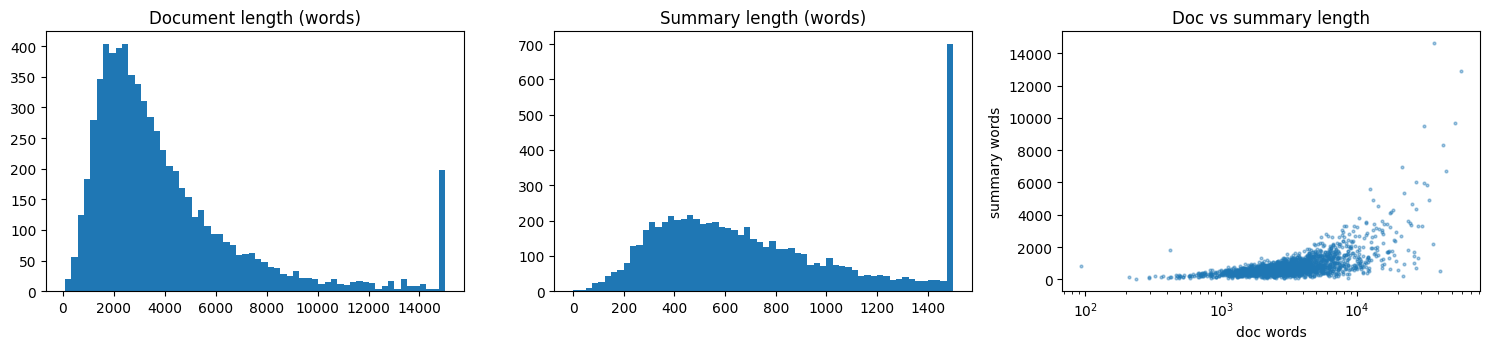

doc words: median 3130 p90 7856 | summary words: median 637 p90 1496 | compression (median) 4.6x


In [15]:
def hf(name):
    return hf_hub_download(HF_DATASET_REPO, f"Phase_6_Summ/{name}", repo_type="dataset", token=HF_TOKEN)
def load_json(name):
    d = json.load(open(hf(name), encoding="utf-8"))
    if isinstance(d, dict): d = [dict(v, id=k) if isinstance(v, dict) else {"id": k, "document": v} for k, v in d.items()]
    return d
def doc_of(r): return r.get("document") or r.get("text") or ""

raw_all, raw_test = load_json("Train/train.json"), load_json("Test/test.json")
print("train docs", len(raw_all), "| test docs", len(raw_test))

# No public dev split -> hold out a validation split (used for epoch selection AND for generation metrics)
idx = list(range(len(raw_all))); random.Random(SEED).shuffle(idx)
val_raw  = [raw_all[i] for i in idx[:PROF["n_val"]]]
pool_raw = [raw_all[i] for i in idx[PROF["n_val"]:]]
train_raw = pool_raw if PROF["n_train"] is None else pool_raw[:PROF["n_train"]]
print("train", len(train_raw), "| val", len(val_raw))

# ---- EDA ----
dw = np.array([len(doc_of(r).split()) for r in pool_raw]); sw = np.array([len(r["summary"].split()) for r in pool_raw])
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
ax[0].hist(np.clip(dw, 0, 15000), bins=60); ax[0].set_title("Document length (words)")
ax[1].hist(np.clip(sw, 0, 1500), bins=60); ax[1].set_title("Summary length (words)")
ax[2].scatter(dw[:2000], sw[:2000], s=4, alpha=.4); ax[2].set_xscale("log"); ax[2].set_xlabel("doc words"); ax[2].set_ylabel("summary words"); ax[2].set_title("Doc vs summary length")
plt.tight_layout(); plt.savefig(f"{PLOT_DIR}/eda.png", dpi=150); plt.show()
print(f"doc words: median {np.median(dw):.0f} p90 {np.percentile(dw,90):.0f} | summary words: median {np.median(sw):.0f} p90 {np.percentile(sw,90):.0f} | compression (median) {np.median(dw/np.maximum(sw,1)):.1f}x")

### Cell 3: Tokenisation (cached) and long-document input strategies

In [16]:
HC = 20000   # chars kept from head and tail of each document for the full tokenisation (middle only reachable via 'select')
def clean(t): return re.sub(r"\s+", " ", t).strip()
def _clip(t):
    if len(t) <= 2 * HC: return t, ""
    h, tl = t[:HC], t[-HC:]
    i = h.rfind(" "); h = h[:i] if i > 0 else h
    j = tl.find(" "); tl = tl[j + 1:] if j >= 0 else tl
    return h, tl
def _tok_doc(t):
    h, tl = _clip(t); ids = tokenizer.encode(h)[1:-1]
    if tl: ids = ids + tokenizer.encode(tl)[1:-1]
    return np.asarray(ids, dtype=np.int32)
def _tok_sum(t): return np.asarray(tokenizer.encode(t)[1:-1], dtype=np.int32)
def pmap(fn, items, desc):
    with mp.get_context("fork").Pool(os.cpu_count() or 2) as pool:
        return list(tqdm(pool.imap(fn, items, chunksize=8), total=len(items), desc=desc))

def make_recs(raw, tag):
    path = f"{OUT}/tok_{tag}_{len(raw)}_{HC}.pkl"
    if os.path.exists(path): return pickle.load(open(path, "rb"))
    docs = [clean(doc_of(r)) for r in raw]; ids = pmap(_tok_doc, docs, f"tokenize {tag} docs")
    has_sum = "summary" in raw[0]; sums = [clean(r["summary"]) for r in raw] if has_sum else None
    sids = pmap(_tok_sum, sums, f"tokenize {tag} summaries") if has_sum else [None] * len(raw)
    recs = [dict(id=str(r["id"]), ids=i, text=d, nw=len(d.split()), sum=s, sum_text=(sums[k] if has_sum else None))
            for k, (r, i, d, s) in enumerate(zip(raw, ids, docs, sids))]
    pickle.dump(recs, open(path, "wb")); return recs

train_recs, val_recs, test_recs = make_recs(train_raw, "train"), make_recs(val_raw, "val"), make_recs(raw_test, "test")
abl_recs = train_recs[:PROF["n_abl"]]; val_gen = val_recs[:PROF["n_gen"]]
tl_ = np.array([len(r["ids"]) for r in train_recs]); sl_ = np.array([len(r["sum"]) for r in train_recs])
print(f"train {len(train_recs)} (abl {len(abl_recs)}) | val {len(val_recs)} (gen {len(val_gen)}) | test {len(test_recs)}")
print(f"doc tokens: median {np.median(tl_):.0f}, p90 {np.percentile(tl_,90):.0f} | > maxdoc({PROF['maxdoc']}): {(tl_>PROF['maxdoc']).mean():.1%}")
print(f"summary tokens: median {np.median(sl_):.0f}, p90 {np.percentile(sl_,90):.0f} | truncated at maxsum({PROF['maxsum']}): {(sl_>=PROF['maxsum']).mean():.1%}")

# ---------- long-document input strategies ----------
CPT = float(np.mean([len(r["text"]) / max(1, len(r["ids"])) for r in train_recs[:200] if len(r["text"]) <= 2 * HC]))   # chars per token
IDF, IDF_MAX = {}, 0.0
def build_idf(recs):
    global IDF_MAX
    dfc = collections.Counter()
    for r in recs[:3000]: dfc.update(set(re.findall(r"[a-z]{3,}", r["text"].lower())))
    N = min(3000, len(recs)); IDF.update({w: math.log(N / (1 + c)) for w, c in dfc.items()}); IDF_MAX = math.log(N)
build_idf(train_recs)
CUE = re.compile(r"\b(held|hold|concluded?|accordingly|dismiss\w*|allow\w*|appeal|section|article|act|rule|therefore|thus|contention|submitted|provision|principle|decision|order|directed?)\b", re.I)
def split_sents(t): return re.split(r"(?<=[.;?!])\s+(?=[A-Z(\"'])", t)

def select_text(t, budget):
    """Importance-based context selection: keep the opening (case header/facts), then the highest-scoring sentences
    (IDF-weighted content words + legal cue words + bonus for the closing 10% = holding), in original order."""
    if len(t) <= budget: return t
    ss = split_sents(t); n = len(ss); keep, used = set(), 0
    for i, s in enumerate(ss):                              # opening ~15% of budget
        if used + len(s) > 0.15 * budget: break
        keep.add(i); used += len(s) + 1
    sc = []
    for i, s in enumerate(ss):
        if i in keep: continue
        w = set(re.findall(r"[a-z]{3,}", s.lower()))
        if len(w) < 4: continue
        v = sum(IDF.get(x, IDF_MAX) for x in w) / (len(w) ** 0.7) + 1.5 * len(CUE.findall(s)) + (3.0 if i >= 0.9 * n else 0.0)
        sc.append((v, i))
    for v, i in sorted(sc, reverse=True):
        if used + len(ss[i]) + 1 > budget: continue
        keep.add(i); used += len(ss[i]) + 1
    return " ".join(ss[i] for i in sorted(keep))

def _sel(args):
    t, M = args; ids = tokenizer.encode(select_text(t, int(M * CPT * 1.02)))[1:-1]
    return np.asarray(ids[:M], dtype=np.int32)
def prep_select(recs, M):
    key = f"sel{M}"; todo = [r for r in recs if key not in r]
    if todo:
        for r, i in zip(todo, pmap(_sel, [(r["text"], M) for r in todo], f"select {M}")): r[key] = i

def get_doc_ids(r, strategy, M):
    ids = r["ids"]
    if len(ids) <= M: return ids
    if strategy == "head": return ids[:M]
    if strategy == "tail": return ids[-M:]
    if strategy == "headtail": h = int(0.6 * M); return np.concatenate([ids[:h], ids[-(M - h):]])
    if strategy == "select": return r[f"sel{M}"]
    raise ValueError(strategy)

SEP = tokenizer.encode("\n\nSummary:")[1:-1]
def build_prompt(r, strategy, M, P=0):
    """[P prompt-placeholders(-1)] [BOS] document tokens [SEP]"""
    return [-1] * P + [BOS] + get_doc_ids(r, strategy, M).tolist() + SEP
def prep(recs_list, spec):
    if spec["strategy"] == "select":
        for rs in recs_list: prep_select(rs, spec["maxdoc"])
print("chars/token", round(CPT, 2), "| separator tokens", len(SEP))

train 6730 (abl 2500) | val 300 (gen 150) | test 100
doc tokens: median 3654, p90 7942 | > maxdoc(1280): 94.3%
summary tokens: median 751, p90 1772 | truncated at maxsum(640): 60.4%
chars/token 4.91 | separator tokens 5


### Cell 4: PEFT modules

In [17]:
class LoRALinear(nn.Module):             # W x + s * B A x
    def __init__(s, base, r=8, alpha=16):
        super().__init__(); s.base, s.scale = base, alpha / r
        s.A = nn.Parameter(torch.randn(r, base.in_features) / math.sqrt(base.in_features))
        s.B = nn.Parameter(torch.zeros(base.out_features, r))
    def forward(s, x): return s.base(x) + (x @ s.A.t() @ s.B.t()) * s.scale

class LoRMALinear(nn.Module):            # multiplicative / output-side update: y + s * B A y
    def __init__(s, base, r=8, alpha=16):
        super().__init__(); s.base, s.scale = base, alpha / r
        s.A = nn.Parameter(torch.randn(r, base.out_features) / math.sqrt(base.out_features))
        s.B = nn.Parameter(torch.zeros(base.out_features, r))
    def forward(s, x):
        y = s.base(x); return y + (y @ s.A.t() @ s.B.t()) * s.scale

class AdaLoRALinear(nn.Module):          # simplified AdaLoRA: SVD-form update + global importance pruning
    def __init__(s, base, r=12, alpha=24):
        super().__init__(); s.base, s.r, s.scale = base, r, alpha / r
        s.P = nn.Parameter(nn.init.orthogonal_(torch.empty(base.out_features, r)))
        s.Q = nn.Parameter(nn.init.orthogonal_(torch.empty(r, base.in_features)))
        s.E = nn.Parameter(torch.zeros(r))
        s.register_buffer("mask", torch.ones(r)); s.register_buffer("imp", torch.zeros(r))
    def forward(s, x): return s.base(x) + (((x @ s.Q.t()) * (s.E * s.mask)) @ s.P.t()) * s.scale
    def orth(s):
        I = torch.eye(s.r, device=s.P.device)
        return ((s.P.t() @ s.P - I) ** 2).sum() + ((s.Q @ s.Q.t() - I) ** 2).sum()

def adalora_update(model, step, total):
    mods = [m for m in model.modules() if isinstance(m, AdaLoRALinear)]
    if not mods: return
    for m in mods:
        if m.E.grad is not None: m.imp.mul_(0.85).add_(0.15 * (m.E.detach() * m.E.grad).abs())
    ti, tf = int(0.15 * total), int(0.75 * total)
    if step < ti: return
    prog = min(1.0, (step - ti) / max(1, tf - ti))
    init = len(mods) * mods[0].r; tgt = int(init * ADA_TARGET); b = int(tgt + (init - tgt) * (1 - prog) ** 3)
    allimp = torch.cat([m.imp for m in mods])
    thr = torch.topk(allimp, b).values[-1] if b < len(allimp) else allimp.min() - 1
    for m in mods: m.mask.copy_((m.imp >= thr).float())

class BiasLinear(nn.Module):             # Phase-1 has bias=False -> BitFit adds zero-init trainable biases
    def __init__(s, base):
        super().__init__(); s.base = base; s.bias = nn.Parameter(torch.zeros(base.out_features))
    def forward(s, x): return s.base(x) + s.bias

class Adapter(nn.Module):                # Houlsby-style bottleneck after every block
    def __init__(s, d, r):
        super().__init__(); s.down, s.up = nn.Linear(d, r), nn.Linear(r, d)
        nn.init.zeros_(s.up.weight); nn.init.zeros_(s.up.bias)
    def forward(s, x): return x + s.up(F.gelu(s.down(x)))

def wrap(module, fn, names=None, skip_names=(), skip_dirs=()):
    for n, c in list(module.named_children()):
        if n in skip_dirs: continue
        if isinstance(c, nn.Linear) and n not in skip_names and (names is None or n in names): setattr(module, n, fn(c))
        else: wrap(c, fn, names, skip_names, skip_dirs)

ATTN_T = {"q_proj", "k_proj", "v_proj", "o_proj", "q_down", "q_up", "kv_down", "kv_up", "k_rope_proj"}

### Cell 5: Generation model and build

In [18]:
def _blk(block, x, rope, pos, mask):
    y, aux, _ = block(x, rope, pos, None, mask); return y, aux

class SumLM(nn.Module):
    """Phase-1 decoder used as a prompt->summary language model (decoder-only 'encoder-decoder by concatenation').
    Supports adapters, prompt tuning (learned virtual tokens), reentrant gradient checkpointing (MoE-safe) and KV-cache decoding."""
    def __init__(s, lm, adapter_dim=0, prompt_len=0, grad_ckpt=True):
        super().__init__(); s.lm, s.P, s.grad_ckpt = lm, prompt_len, grad_ckpt
        D = lm.cfg.d_model
        s.adapters = nn.ModuleList([Adapter(D, adapter_dim) for _ in lm.blocks]) if adapter_dim else None
        if prompt_len:
            s.prompt = nn.Parameter(lm.tok_emb.weight.detach()[torch.randint(0, lm.cfg.vocab_size, (prompt_len,))].float().clone())
    def embed(s, ids, positions):
        lm = s.lm; x = lm.tok_emb(ids.clamp(min=0))
        if s.P:
            sent = ids < 0                                       # prompt placeholders (exactly P per row, in order)
            if sent.any(): x = x.clone(); x[sent] = s.prompt.repeat(ids.size(0), 1).to(x.dtype)
        if lm.sin_emb is not None: x = x * math.sqrt(lm.cfg.d_model) + lm.sin_emb.pe[positions].to(x.dtype)
        return x
    def trunk(s, x, positions, attn_mask=None, caches=None, ckpt=False):
        lm = s.lm; aux = x.new_zeros(()); new = []
        for i, b in enumerate(lm.blocks):
            if ckpt:
                if not x.requires_grad: x = x.requires_grad_(True)        # reentrant ckpt needs a grad-requiring input (frozen embeddings)
                x, a = checkpoint(lambda t, b=b: _blk(b, t, lm.rope, positions, attn_mask), x, use_reentrant=True); nc = None   # MoE routing breaks non-reentrant ckpt
            else: x, a, nc = b(x, lm.rope, positions, None if caches is None else caches[i], attn_mask)
            aux = aux + a; new.append(nc)
            if s.adapters is not None: x = s.adapters[i](x)
        return lm.final_norm(x), aux, new
    def forward_train(s, ids, labels):
        """ids/labels [B,T] right-padded, causal. Returns hidden states at positions predicting a summary token, the targets, aux loss."""
        T = ids.size(1); pos = torch.arange(T, device=ids.device); x = s.embed(ids, pos)
        h, aux, _ = s.trunk(x, pos, None, None, ckpt=s.grad_ckpt and s.training and torch.is_grad_enabled())
        tgt = labels[:, 1:]; sel = tgt != -100
        return h[:, :-1][sel], tgt[sel], aux
    def step(s, ids, attn, caches):
        """Left-padded prefill or one decode step with KV cache. attn: [B, past+T] (1 = real token). Returns last-position logits."""
        B, T = ids.shape; past = 0 if caches is None else caches[0][0].size(2); dev = ids.device
        am = attn.bool(); positions = (am.long().cumsum(-1) - 1).clamp(min=0)[:, past:]
        q = torch.arange(past, past + T, device=dev)[:, None]; k = torch.arange(past + T, device=dev)[None, :]
        mask = ((k <= q)[None, None] & am[:, None, None, :]) | (k == q)[None, None]
        h, _, new = s.trunk(s.embed(ids, positions), positions, mask, caches)
        return s.lm.lm_head(h[:, -1]), new

def build(spec):
    lm = load_phase1(spec["variant"], pretrained=spec["init"] == "phase1"); m = spec["method"]; ad, pl = 0, 0
    if spec.get("student"):
        lm.blocks = nn.ModuleList([lm.blocks[i] for i in STUDENT_KEEP]); lm.cfg = copy.copy(lm.cfg); lm.cfg.n_layers = len(STUDENT_KEEP)
    if m not in ("full", "kd", "kd_control"):
        for p in lm.parameters(): p.requires_grad = False
    if m == "partial":
        for b in lm.blocks[-4:]:
            for p in b.parameters(): p.requires_grad = True
        for p in lm.final_norm.parameters(): p.requires_grad = True
    elif m == "bitfit":
        wrap(lm.blocks, BiasLinear, skip_names={"router"})
        for n, p in lm.named_parameters():
            if "norm" in n: p.requires_grad = True
    elif m == "lora":    wrap(lm.blocks, lambda b: LoRALinear(b, 8, 16), ATTN_T, skip_dirs={"experts", "shared"})
    elif m == "lorma":   wrap(lm.blocks, lambda b: LoRMALinear(b, 8, 16), ATTN_T, skip_dirs={"experts", "shared"})
    elif m == "adalora": wrap(lm.blocks, lambda b: AdaLoRALinear(b, 12, 24), ATTN_T, skip_dirs={"experts", "shared"})
    elif m == "adapter": ad = 64
    elif m == "prompt":  pl = PROMPT_LEN
    return SumLM(lm, ad, pl).to(DEVICE)

def count_params(model):
    return sum(p.numel() for p in model.parameters()), sum(p.numel() for p in model.parameters() if p.requires_grad)

### Cell 6: Decoding and metrics

In [19]:
# ---------------- decoding ----------------
@torch.no_grad()
def generate(model, prompts, max_new=300, min_new=0, temperature=0.0, top_k=0, top_p=1.0, rep_pen=1.0, no_repeat=0, bs=8, desc=None):
    """Batched KV-cache decoding (left-padded). Greedy when temperature<=0. Returns generated token lists (EOS stripped)."""
    model.eval(); order = np.argsort([-len(p) for p in prompts]); outs = [None] * len(prompts)
    for a in tqdm(range(0, len(prompts), bs), desc=desc, disable=desc is None, leave=False):
        ix = order[a:a + bs]; batch = [prompts[i] for i in ix]; B = len(batch); L = max(map(len, batch))
        assert L + max_new <= model.lm.cfg.max_seq_len, f"prompt {L} + max_new {max_new} exceeds max_seq_len"
        ids = torch.full((B, L), PAD, dtype=torch.long); am = torch.zeros(B, L, dtype=torch.long)
        for j, p in enumerate(batch): ids[j, L - len(p):] = torch.tensor(p); am[j, L - len(p):] = 1
        cur, attn = ids.to(DEVICE), am.to(DEVICE); caches = None; gen = []
        done = torch.zeros(B, dtype=torch.bool, device=DEVICE); hist = [[] for _ in range(B)]; seen = [dict() for _ in range(B)]
        for t in range(max_new):
            with amp(): lg, caches = model.step(cur, attn, caches)
            lg = lg.float(); lg[:, PAD] = float("-inf"); lg[:, BOS] = float("-inf")
            if t < min_new: lg[:, EOS] = float("-inf")
            if rep_pen != 1.0 and gen:
                rec = torch.stack(gen, 1)[:, -128:]; sc = torch.gather(lg, 1, rec)
                lg.scatter_(1, rec, torch.where(sc > 0, sc / rep_pen, sc * rep_pen))
            if no_repeat > 1:
                for b in range(B):
                    if len(hist[b]) >= no_repeat - 1:
                        ban = seen[b].get(tuple(hist[b][-(no_repeat - 1):]))
                        if ban: lg[b, list(ban)] = float("-inf")
            if temperature <= 0: nxt = lg.argmax(-1, keepdim=True)
            else:
                lg = lg / temperature
                if top_k: lg = lg.masked_fill(lg < torch.topk(lg, top_k).values[:, -1, None], float("-inf"))
                if top_p < 1.0:
                    sl, si = torch.sort(lg, descending=True, dim=-1); pr = torch.softmax(sl, -1)
                    lg = torch.full_like(lg, float("-inf")).scatter(1, si, sl.masked_fill(pr.cumsum(-1) - pr > top_p, float("-inf")))
                nxt = torch.multinomial(torch.softmax(lg, -1), 1)
            nxt = torch.where(done.unsqueeze(1), torch.full_like(nxt, PAD), nxt)
            if no_repeat > 1:
                for b, tk in enumerate(nxt.squeeze(1).tolist()):
                    if done[b]: continue
                    h = hist[b]
                    if len(h) >= no_repeat - 1: seen[b].setdefault(tuple(h[-(no_repeat - 1):]), set()).add(tk)
                    h.append(tk)
            gen.append(nxt.squeeze(1)); done |= nxt.squeeze(1) == EOS
            cur = nxt; attn = torch.cat([attn, torch.ones(B, 1, dtype=attn.dtype, device=DEVICE)], 1)
            if done.all(): break
        G = torch.stack(gen, 1).tolist()
        for j, g in enumerate(G): outs[ix[j]] = g[:g.index(EOS)] if EOS in g else [x for x in g if x != PAD]
    return outs

def trim_incomplete(t):
    """Drop a trailing unfinished sentence (generation hit the length cap)."""
    t = t.strip(); k = max(t.rfind(". "), t.rfind(".]"), t.rfind("; ")); 
    return t if t.endswith((".", "]", ")")) or k < 0.5 * len(t) else t[:k + 1]
def lead_words(text, n=100): return " ".join(text.split()[:n])
def finalize(ids, rec, cut=True):
    t = tokenizer.decode(ids).strip(); t = trim_incomplete(t) if cut else t
    return t if len(t.split()) >= 5 else lead_words(rec["text"])

DEC = dict(max_new=PROF["gen_new"], min_new=60, temperature=0.0, rep_pen=1.15, no_repeat=4)

# ---------------- metrics ----------------
RS = rouge_scorer.RougeScorer(["rouge1", "rougeL"], use_stemmer=True)
def rouge_docs(cands, refs):
    s = [RS.score(r, c) for c, r in zip(cands, refs)]
    return [x["rouge1"].fmeasure for x in s], [x["rougeL"].fmeasure for x in s]

_BS = None
def bert_docs(cands, refs):
    """Per-document BERTScore F1 (no baseline rescaling). Returns None if the scorer cannot be loaded (no internet)."""
    global _BS
    try:
        if _BS is None:
            from bert_score import BERTScorer
            _BS = BERTScorer(model_type=BS_MODEL, lang="en", device=DEVICE) if BS_MODEL else BERTScorer(lang="en", device=DEVICE)
        with torch.no_grad(): return _BS.score(cands, refs, batch_size=16)[2].tolist()
    except Exception as e:
        print("BERTScore unavailable -> ROUGE-L is used as the selection score:", repr(e)[:150]); return None

def rep4(t):
    w = t.lower().split(); g = [tuple(w[i:i + 4]) for i in range(len(w) - 3)]
    return 1 - len(set(g)) / max(1, len(g))
ENT = re.compile(r"\b\d[\d,./]*\b|\b[A-Z][a-z]{3,}\b")
def unsupported(summ, doc):
    """Factuality proxy: share of numbers / capitalised names in the summary that never occur in the source document."""
    toks = ENT.findall(summ)
    return sum(1 for x in toks if x not in doc) / max(1, len(toks))

def evaluate(cands, refs, docs):
    r1, rl = rouge_docs(cands, refs); bs = bert_docs(cands, refs); prim = bs if bs is not None else rl
    return dict(r1=float(np.mean(r1)), rL=float(np.mean(rl)), bs=float(np.mean(bs)) if bs is not None else float("nan"),
                score=float(np.mean(prim)), score_doc=[float(x) for x in prim], rL_doc=[float(x) for x in rl],
                words=float(np.mean([len(c.split()) for c in cands])), rep4=float(np.mean([rep4(c) for c in cands])),
                unsup=float(np.mean([unsupported(c, d) for c, d in zip(cands, docs)])))

### Cell 7: Training (resumable)

In [20]:
class SumDS(Dataset):
    def __init__(s, recs, strategy, maxdoc, maxsum, P): s.recs, s.st, s.M, s.S, s.P = recs, strategy, maxdoc, maxsum, P
    def __len__(s): return len(s.recs)
    def __getitem__(s, i):
        r = s.recs[i]; pr = build_prompt(r, s.st, s.M, s.P); sm = r["sum"][:s.S - 1].tolist() + [EOS]
        return i, torch.tensor(pr + sm), torch.tensor([-100] * len(pr) + sm)
def collate(b):
    T = max(len(x[1]) for x in b); ids = torch.full((len(b), T), PAD, dtype=torch.long); lab = torch.full((len(b), T), -100, dtype=torch.long)
    for i, (_, a, l) in enumerate(b): ids[i, :len(a)] = a; lab[i, :len(l)] = l
    return torch.tensor([x[0] for x in b]), ids, lab

@torch.no_grad()
def val_loss(model, recs, spec):
    """Mean token cross-entropy on reference summaries (threshold-free, cheap model-selection criterion)."""
    model.eval(); tot, n = 0.0, 0
    for _, ids, lab in DataLoader(SumDS(recs, spec["strategy"], spec["maxdoc"], spec["maxsum"], model.P), batch_size=MBS, collate_fn=collate, num_workers=2):
        with amp(): hs, tg, _ = model.forward_train(ids.to(DEVICE), lab.to(DEVICE)); lg = model.lm.lm_head(hs)
        tot += F.cross_entropy(lg.float(), tg, reduction="sum").item(); n += tg.numel()
    return tot / max(1, n)

def snap(model, full):
    sd = model.state_dict()
    if full: keys = list(sd)
    else:
        tn = {n for n, p in model.named_parameters() if p.requires_grad}; keys = [k for k in sd if k in tn or k.endswith(".mask")]
    return {k: sd[k].detach().cpu().clone() for k in keys}

SAVE_EVERY = 100
def _atomic_save(obj, path): tmp = path + ".tmp"; torch.save(obj, tmp); os.replace(tmp, path)
LR = dict(full=5e-5, partial=1e-4, bitfit=1e-3, lora=5e-4, lorma=5e-4, adalora=1e-3, adapter=5e-4, prompt=1e-2, kd=5e-5, kd_control=5e-5)

def fit(model, name, tr_recs, dv_recs, *, spec, epochs, kd=None, wd=0.01, resume=True):
    method = spec["method"]; lr = LR[method]; accum = max(1, EFF_DOCS // MBS); n = len(tr_recs); nb_total = math.ceil(n / MBS)
    total = epochs * math.ceil(nb_total / accum); warm = max(1, int(0.06 * total))
    opt = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=lr, weight_decay=wd)
    scaler = torch.amp.GradScaler("cuda", enabled=USE_SCALER)
    ada = [m for m in model.modules() if isinstance(m, AdaLoRALinear)]
    full_snap = method in ("full", "kd", "kd_control"); aux_c = model.lm.cfg.aux_loss_coef
    last_p, best_p = f"{CKPT_DIR}/{name}_last.pt", f"{CKPT_DIR}/{name}_bestsd.pt"
    start_ep, skip_b, gstep, best_v, hist, carry = 0, 0, 0, float("inf"), [], (0.0, 0)
    if resume and os.path.exists(last_p):
        st = torch.load(last_p, map_location="cpu", weights_only=False)
        model.load_state_dict({k: v.to(DEVICE) for k, v in st["model"].items()}, strict=False); opt.load_state_dict(st["opt"])
        if st.get("scaler") and USE_SCALER: scaler.load_state_dict(st["scaler"])
        start_ep, skip_b, gstep, best_v, hist, carry = st["epoch"], st["batch"], st["gstep"], st["best_v"], st["hist"], (st["tl"], st["nb"])
        torch.set_rng_state(st["rng_cpu"])
        if DEVICE.type == "cuda": torch.cuda.set_rng_state(st["rng_cuda"])
        del st; gc.collect(); print(f"[{name}] RESUMED epoch {start_ep+1}/{epochs}, batch {skip_b}/{nb_total}, step {gstep}/{total}")

    def save_last(ep, batch, tl, nb):
        _atomic_save(dict(model=snap(model, full_snap), opt=opt.state_dict(), scaler=scaler.state_dict() if USE_SCALER else None,
                          epoch=ep, batch=batch, gstep=gstep, best_v=best_v, hist=hist, tl=tl, nb=nb, rng_cpu=torch.get_rng_state(),
                          rng_cuda=torch.cuda.get_rng_state() if DEVICE.type == "cuda" else None), last_p)

    ds = SumDS(tr_recs, spec["strategy"], spec["maxdoc"], spec["maxsum"], model.P)
    for ep in range(start_ep, epochs):
        model.train(); t0 = time.time()
        order = np.random.RandomState(SEED + ep).permutation(n).tolist()
        first_b = skip_b if ep == start_ep else 0; tl, nb = carry if (ep == start_ep and first_b > 0) else (0.0, 0)
        loader = DataLoader(Subset(ds, order[first_b * MBS:]), batch_size=MBS, shuffle=False, collate_fn=collate, num_workers=2)
        opt.zero_grad(set_to_none=True)
        for bi, (idx, ids, lab) in enumerate(tqdm(loader, desc=f"{name} ep{ep+1}/{epochs}", leave=False)):
            b = first_b + bi; ids, lab = ids.to(DEVICE), lab.to(DEVICE)
            with amp(): hs, tg, aux = model.forward_train(ids, lab); lg = model.lm.lm_head(hs)
            ce = F.cross_entropy(lg.float(), tg)
            if kd is not None:                                        # token-level logit KD + hidden-state (cosine) KD from the teacher
                with torch.no_grad(), amp(): ths, _, _ = kd["teacher"].forward_train(ids, lab); tlg = kd["teacher"].lm.lm_head(ths)
                T = kd["T"]; klv = F.kl_div(F.log_softmax(lg.float() / T, -1), F.softmax(tlg.float() / T, -1), reduction="batchmean") * T * T
                cosl = 1 - F.cosine_similarity(hs.float(), ths.float(), dim=-1).mean()
                ls = kd["alpha"] * ce + (1 - kd["alpha"]) * klv + kd["beta"] * cosl
            else: ls = ce
            ls = ls + aux_c * aux.float()
            if ada: ls = ls + 0.1 * sum(m.orth() for m in ada) / len(ada)
            scaler.scale(ls / accum).backward(); tl += float(ls.detach()); nb += 1
            if (b + 1) % accum == 0 or b + 1 == nb_total:
                f = (gstep + 1) / warm if gstep < warm else 0.1 + 0.45 * (1 + math.cos(math.pi * (gstep - warm) / max(1, total - warm)))
                for g in opt.param_groups: g["lr"] = lr * f
                scaler.unscale_(opt); torch.nn.utils.clip_grad_norm_([p for p in model.parameters() if p.requires_grad], 1.0)
                if method == "adalora": adalora_update(model, gstep, total)
                scaler.step(opt); scaler.update(); opt.zero_grad(set_to_none=True); gstep += 1
                if gstep % SAVE_EVERY == 0 and b + 1 < nb_total: save_last(ep, b + 1, tl, nb)
        vl = val_loss(model, dv_recs, spec)
        hist.append(dict(epoch=ep + 1, train_loss=tl / max(1, nb), val_loss=vl, sec=time.time() - t0))
        print(f"[{name}] ep{ep+1} train {tl/max(1,nb):.3f} | val CE {vl:.4f} (ppl {math.exp(vl):.1f}) | {time.time()-t0:.0f}s")
        if vl < best_v: best_v = vl; _atomic_save(snap(model, full_snap), best_p)
        save_last(ep + 1, 0, 0.0, 0); carry = (0.0, 0)
    best = torch.load(best_p, map_location="cpu", weights_only=False)
    model.load_state_dict({k: v.to(DEVICE) for k, v in best.items()}, strict=False)
    return hist, best

### Cell 8: Experiment runner (cached)

In [21]:
RES = {}
for fn in os.listdir(RES_DIR):
    if fn.endswith(".json"): RES[fn[:-5]] = json.load(open(f"{RES_DIR}/{fn}"))
print("cached runs:", list(RES))

DEF_STRAT = "headtail"
def spec_of(variant, method, **kw):
    d = dict(variant=variant, method=method, init="phase1", strategy=DEF_STRAT, maxdoc=PROF["maxdoc"], maxsum=PROF["maxsum"], student=False)
    d.update(kw); return d

def load_model(name):
    m = build(RES[name]["spec"]); m.load_state_dict(torch.load(RES[name]["ckpt"], map_location=DEVICE), strict=False); return m.eval()

def gen_texts(model, spec, recs, dec=None, desc=None):
    prep([recs], spec); d = dict(DEC); d.update(dec or {})
    prompts = [build_prompt(r, spec["strategy"], spec["maxdoc"], model.P) for r in recs]
    return [finalize(o, r, cut=(len(o) >= d["max_new"])) for o, r in zip(generate(model, prompts, desc=desc, **d), recs)]

def run(name, spec, *, group, train_set, epochs, kd=None):
    if name in RES: print(f"[{name}] cached  score={RES[name]['score']:.4f}"); return RES[name]
    seed_all(); prep([train_set, val_recs, val_gen], spec)
    model = build(spec); tot, trn = count_params(model)
    print(f"\n=== {name} | total {tot/1e6:.1f}M trainable {trn/1e6:.2f}M ({100*trn/tot:.2f}%)")
    if DEVICE.type == "cuda": torch.cuda.reset_peak_memory_stats()
    t0 = time.time(); hist, best = fit(model, name, train_set, val_recs, spec=spec, epochs=epochs, kd=kd); train_sec = time.time() - t0
    peak = torch.cuda.max_memory_allocated() / 2**30 if DEVICE.type == "cuda" else 0.0
    ck = f"{CKPT_DIR}/{name}.pt"; torch.save(best, ck)
    if DEVICE.type == "cuda": torch.cuda.reset_peak_memory_stats()
    t1 = time.time(); texts = gen_texts(model, spec, val_gen, desc="val gen"); gsec = (time.time() - t1) / len(val_gen)
    gpeak = torch.cuda.max_memory_allocated() / 2**30 if DEVICE.type == "cuda" else 0.0
    ev = evaluate(texts, [r["sum_text"] for r in val_gen], [r["text"] for r in val_gen])
    out = dict(spec=spec, group=group, ckpt=ck, hist=hist, val_loss=min(h["val_loss"] for h in hist),
               trainable_M=trn / 1e6, total_M=tot / 1e6, peak_gb=peak, gen_peak_gb=gpeak, train_sec=train_sec, gen_s_per_doc=gsec,
               epochs=epochs, n_train=len(train_set), **ev)
    json.dump(texts, open(f"{GEN_DIR}/val_{name}.json", "w")); json.dump(out, open(f"{RES_DIR}/{name}.json", "w"), indent=1); RES[name] = out
    print(f"[{name}] DONE ROUGE-1 {ev['r1']:.4f} ROUGE-L {ev['rL']:.4f} BERTScore {ev['bs']:.4f} | words {ev['words']:.0f} rep4 {ev['rep4']:.3f} unsup {ev['unsup']:.3f} | train {train_sec/60:.1f} min, gen {gsec:.1f}s/doc")
    for sfx in ("_last.pt", "_bestsd.pt"):
        p_ = f"{CKPT_DIR}/{name}{sfx}"
        if os.path.exists(p_): os.remove(p_)
    del model, best; gc.collect(); torch.cuda.empty_cache(); return out

cached runs: ['D__clean_gqa_rope_moe__kd', 'B__clean_gqa_rope_moe__adapter', 'B__clean_gqa_rope_moe__full']


### Cell 9: Study A, baselines, coverage, input strategy

config.json:   0%|          | 0.00/482 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.42GB            

... (5 outputs left out)

select 768:   0%|          | 0/150 [00:00<?, ?it/s]

select 1536:   0%|          | 0/150 [00:00<?, ?it/s]

select 2304:   0%|          | 0/150 [00:00<?, ?it/s]

reference-content coverage of the input window (rows = max input tokens):
       head   tail  headtail  select
384   0.190  0.250     0.200   0.213
768   0.324  0.394     0.363   0.356
1536  0.495  0.552     0.553   0.541
2304  0.602  0.650     0.645   0.645


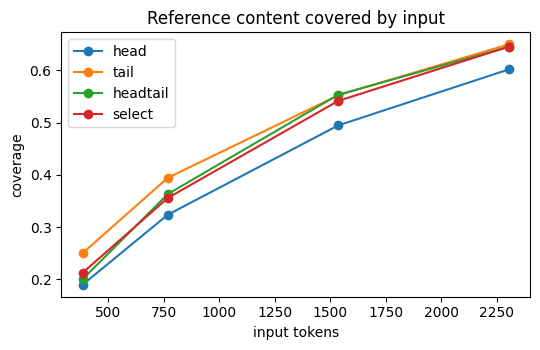


=== A__headtail | total 152.1M trainable 152.13M (100.00%)


A__headtail ep1/2:   0%|          | 0/300 [00:00<?, ?it/s]

KeyboardInterrupt: 

In [28]:
# ---- (1) model-free baselines: lead-N words and importance-based extractive selection ----
refs_g = [r["sum_text"] for r in val_gen]; docs_g = [r["text"] for r in val_gen]
tw = int(np.mean([len(x.split()) for x in refs_g])); tc = int(np.mean([len(x) for x in refs_g]))
BASE_RES = {"lead-N words": evaluate([lead_words(d, tw) for d in docs_g], refs_g, docs_g),
            "select (extractive)": evaluate([select_text(d, tc) for d in docs_g], refs_g, docs_g)}
print(pd.DataFrame({k: {m: v[m] for m in ("r1", "rL", "bs", "words", "unsup")} for k, v in BASE_RES.items()}).T.round(4))

# ---- (2) information coverage of each input strategy (model-free): share of reference content tokens present in the model input ----
freq = collections.Counter()
for r in train_recs[:2000]: freq.update(r["ids"].tolist())
common = {t for t, _ in freq.most_common(150)}
def coverage(strategy, M):
    prep_select(val_recs, M) if strategy == "select" else None
    c = []
    for r in val_recs:
        ref = set(r["sum"].tolist()) - common
        if ref: c.append(len(ref & set(get_doc_ids(r, strategy, M).tolist())) / len(ref))
    return float(np.mean(c))
Ms = [PROF["maxdoc"] // 2, PROF["maxdoc"], 2 * PROF["maxdoc"], 3 * PROF["maxdoc"]]
COV = pd.DataFrame({s: [coverage(s, M) for M in Ms] for s in ("head", "tail", "headtail", "select")}, index=Ms)
print("reference-content coverage of the input window (rows = max input tokens):"); print(COV.round(3))
ax = COV.plot(marker="o", figsize=(5.5, 3.6), title="Reference content covered by input"); ax.set_xlabel("input tokens"); ax.set_ylabel("coverage")
plt.tight_layout(); plt.savefig(f"{PLOT_DIR}/coverage.png", dpi=150); plt.show()

# ---- (3) Study A: input strategy / context length (full fine-tuning on the ablation subset) ----
A_OVR = {"headtail": {}, "head": dict(strategy="head"), "tail": dict(strategy="tail"), "select": dict(strategy="select"),
         "half_context": dict(maxdoc=PROF["maxdoc"] // 2)}
for tag, ov in A_OVR.items():
    run(f"A__{tag}", spec_of(BASE_VARIANT, "full", **ov), group="repr", train_set=abl_recs, epochs=PROF["ep"])
best_strat = max(["headtail", "head", "tail", "select"], key=lambda t: RES[f"A__{t}"]["score"])
REP = dict(strategy=A_OVR[best_strat].get("strategy", DEF_STRAT))
print("Selected input strategy:", REP, "| scores:", {t: round(RES[f"A__{t}"]["score"], 4) for t in A_OVR})

### Cell 10: Study B, adaptation technique

In [44]:
# TECH = ["full", "partial", "bitfit", "lora", "lorma", "adalora", "adapter", "prompt"]
TECH = ["full"]
REP = dict(strategy = DEF_STRAT)
for m in TECH:
    run(f"B__{BASE_VARIANT}__{m}", spec_of(BASE_VARIANT, m, **REP), group="tech", train_set=train_recs, epochs=PROF["ep"])
# control for "does Phase-1 domain pre-training help?": same architecture, random init (analysis only, never submitted)
# run(f"B__{BASE_VARIANT}__scratch", spec_of(BASE_VARIANT, "full", init="scratch", **REP), group="tech", train_set=train_recs, epochs=PROF["ep"])


=== B__clean_gqa_rope_moe__full | total 152.1M trainable 152.13M (100.00%)


B__clean_gqa_rope_moe__full ep1/2:   0%|          | 0/1683 [00:00<?, ?it/s]

[B__clean_gqa_rope_moe__full] ep1 train 2.486 | val CE 2.2057 (ppl 9.1) | 1616s


B__clean_gqa_rope_moe__full ep2/2:   0%|          | 0/1683 [00:00<?, ?it/s]

[B__clean_gqa_rope_moe__full] ep2 train 2.189 | val CE 2.1793 (ppl 8.8) | 1621s


val gen:   0%|          | 0/19 [00:00<?, ?it/s]

... (6 outputs left out)

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/389 [00:00<?, ?it/s]

[transformers] RobertaModel LOAD REPORT from: roberta-large
Key                       | Status     | 
--------------------------+------------+-
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.dense.weight      | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
pooler.dense.bias         | MISSING    | 
pooler.dense.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


[B__clean_gqa_rope_moe__full] DONE ROUGE-1 0.4491 ROUGE-L 0.2298 BERTScore 0.8426 | words 360 rep4 0.012 unsup 0.165 | train 54.1 min, gen 4.5s/doc


In [45]:
name = f"B__{BASE_VARIANT}__full"            # change to any finished run, e.g. f"B__{BASE_VARIANT}__lorma"
assert name in RES, f"{name} not found; finished runs: {list(RES)}"

def write_sub(tag, texts):
    ids = [r["id"] for r in test_recs]
    assert len(texts) == len(ids) == len(set(ids)) == len(raw_test) and set(ids) == {str(t["id"]) for t in raw_test}
    assert all(isinstance(t, str) and t.strip() for t in texts), "empty summary"
    d = f"{OUT}/sub_{tag}"; os.makedirs(d, exist_ok=True)
    json.dump([{"id": i, "summary": t} for i, t in zip(ids, texts)], open(f"{d}/prediction.json", "w"))
    zp = f"/kaggle/working/submission_{tag}.zip"
    with zipfile.ZipFile(zp, "w", zipfile.ZIP_DEFLATED) as z: z.write(f"{d}/prediction.json", arcname="prediction.json")
    print(f"saved {zp} | {len(texts)} summaries, avg {np.mean([len(t.split()) for t in texts]):.0f} words"); return zp

path = f"{GEN_DIR}/test_{name}.json"             # cached, so a restart doesn't regenerate
if os.path.exists(path): texts = json.load(open(path))
else:
    m = load_model(name); texts = gen_texts(m, RES[name]["spec"], test_recs, desc=f"test:{name}")
    json.dump(texts, open(path, "w")); del m; gc.collect(); torch.cuda.empty_cache()

print(f"val: BERTScore {RES[name]['bs']:.4f} | ROUGE-1 {RES[name]['r1']:.4f} | ROUGE-L {RES[name]['rL']:.4f}")
zp = write_sub(name, texts)
# shutil.copy(zp, "/kaggle/working/submission.zip");
# print("copied to /kaggle/working/submission.zip")

test:B__clean_gqa_rope_moe__full:   0%|          | 0/13 [00:00<?, ?it/s]

val: BERTScore 0.8426 | ROUGE-1 0.4491 | ROUGE-L 0.2298
saved /kaggle/working/submission_B__clean_gqa_rope_moe__full.zip | 100 summaries, avg 361 words


### Cell 11: Study C, all four Phase 1 architectures

In [ ]:
ARCH_METHODS = ["full"]            # add "lorma" to compare the parameter-efficient method on every architecture too
for v in VARIANTS:
    for m in ARCH_METHODS:
        run(f"B__{v}__{m}", spec_of(v, m, **REP), group="arch", train_set=train_recs, epochs=PROF["ep"])

### Cell 12: Study D, knowledge distillation

In [22]:
def write_sub(tag, texts):
    ids = [r["id"] for r in test_recs]
    assert len(texts) == len(ids) == len(set(ids)) == len(raw_test) and set(ids) == {str(t["id"]) for t in raw_test}
    assert all(isinstance(t, str) and t.strip() for t in texts), "empty summary"
    d = f"{OUT}/sub_{tag}"; os.makedirs(d, exist_ok=True)
    json.dump([{"id": i, "summary": t} for i, t in zip(ids, texts)], open(f"{d}/prediction.json", "w"))
    zp = f"/kaggle/working/submission_{tag}.zip"
    with zipfile.ZipFile(zp, "w", zipfile.ZIP_DEFLATED) as z: z.write(f"{d}/prediction.json", arcname="prediction.json")
    print(f"saved {zp} | {len(texts)} summaries, avg {np.mean([len(t.split()) for t in texts]):.0f} words"); return zp


In [46]:
teacher_name, kd_name = f"B__{BASE_VARIANT}__full", f"D__{BASE_VARIANT}__kd"
stu = dict(RES[teacher_name]["spec"], method="kd", student=True)       # same input format; 4 of the 16 pretrained blocks
if kd_name not in RES:
    teacher = load_model(teacher_name).eval(); teacher.grad_ckpt = False
    for p in teacher.parameters(): p.requires_grad = False
    run(kd_name, stu, group="kd", train_set=train_recs, epochs=PROF["ep"], kd=dict(teacher=teacher, T=2.0, alpha=0.5, beta=0.5))
    del teacher; gc.collect(); torch.cuda.empty_cache()
# run(f"D__{BASE_VARIANT}__kd_control", dict(stu, method="kd_control"), group="kd", train_set=train_recs, epochs=PROF["ep"])


=== D__clean_gqa_rope_moe__kd | total 53.3M trainable 53.34M (100.00%)


D__clean_gqa_rope_moe__kd ep1/2:   0%|          | 0/1683 [00:00<?, ?it/s]

[D__clean_gqa_rope_moe__kd] ep1 train 2.601 | val CE 3.2666 (ppl 26.2) | 874s


D__clean_gqa_rope_moe__kd ep2/2:   0%|          | 0/1683 [00:00<?, ?it/s]

[D__clean_gqa_rope_moe__kd] ep2 train 2.127 | val CE 3.1470 (ppl 23.3) | 872s


val gen:   0%|          | 0/19 [00:00<?, ?it/s]

[D__clean_gqa_rope_moe__kd] DONE ROUGE-1 0.3904 ROUGE-L 0.2027 BERTScore 0.8305 | words 316 rep4 0.009 unsup 0.242 | train 29.2 min, gen 1.1s/doc


In [47]:
name = f"D__{BASE_VARIANT}__kd"            # change to any finished run, e.g. f"B__{BASE_VARIANT}__lorma"
assert name in RES, f"{name} not found; finished runs: {list(RES)}"

path = f"{GEN_DIR}/test_{name}.json"             # cached, so a restart doesn't regenerate
if os.path.exists(path): texts = json.load(open(path))
else:
    m = load_model(name); texts = gen_texts(m, RES[name]["spec"], test_recs, desc=f"test:{name}")
    json.dump(texts, open(path, "w")); del m; gc.collect(); torch.cuda.empty_cache()

print(f"val: BERTScore {RES[name]['bs']:.4f} | ROUGE-1 {RES[name]['r1']:.4f} | ROUGE-L {RES[name]['rL']:.4f}")
zp = write_sub(name, texts)
# shutil.copy(zp, "/kaggle/working/submission.zip");
# print("copied to /kaggle/working/submission.zip")

test:D__clean_gqa_rope_moe__kd:   0%|          | 0/13 [00:00<?, ?it/s]

val: BERTScore 0.8305 | ROUGE-1 0.3904 | ROUGE-L 0.2027
saved /kaggle/working/submission_D__clean_gqa_rope_moe__kd.zip | 100 summaries, avg 347 words


In [56]:
REP = dict(strategy = DEF_STRAT)
run(f"B__{BASE_VARIANT}__adapter", spec_of(BASE_VARIANT, "adapter", **REP), group="tech", train_set=train_recs, epochs=3)
name = f"B__{BASE_VARIANT}__adapter"            # change to any finished run, e.g. f"B__{BASE_VARIANT}__lorma"
assert name in RES, f"{name} not found; finished runs: {list(RES)}"

path = f"{GEN_DIR}/test_{name}.json"             # cached, so a restart doesn't regenerate
if os.path.exists(path): texts = json.load(open(path))
else:
    m = load_model(name); texts = gen_texts(m, RES[name]["spec"], test_recs, desc=f"test:{name}")
    json.dump(texts, open(path, "w")); del m; gc.collect(); torch.cuda.empty_cache()

print(f"val: BERTScore {RES[name]['bs']:.4f} | ROUGE-1 {RES[name]['r1']:.4f} | ROUGE-L {RES[name]['rL']:.4f}")
zp = write_sub(name, texts)

run(f"B__{BASE_VARIANT}__full", spec_of(BASE_VARIANT, "full", **REP), group="tech", train_set=train_recs, epochs=5)
name = f"B__{BASE_VARIANT}__full"            # change to any finished run, e.g. f"B__{BASE_VARIANT}__lorma"
assert name in RES, f"{name} not found; finished runs: {list(RES)}"

path = f"{GEN_DIR}/test_{name}.json"             # cached, so a restart doesn't regenerate
if os.path.exists(path): texts = json.load(open(path))
else:
    m = load_model(name); texts = gen_texts(m, RES[name]["spec"], test_recs, desc=f"test:{name}")
    json.dump(texts, open(path, "w")); del m; gc.collect(); torch.cuda.empty_cache()

print(f"val: BERTScore {RES[name]['bs']:.4f} | ROUGE-1 {RES[name]['r1']:.4f} | ROUGE-L {RES[name]['rL']:.4f}")
zp = write_sub(name, texts)

[B__clean_gqa_rope_moe__adapter] cached  score=0.8455
val: BERTScore 0.8455 | ROUGE-1 0.4362 | ROUGE-L 0.2312
saved /kaggle/working/submission_B__clean_gqa_rope_moe__adapter.zip | 100 summaries, avg 359 words

=== B__clean_gqa_rope_moe__full | total 152.1M trainable 152.13M (100.00%)


B__clean_gqa_rope_moe__full ep1/5:   0%|          | 0/1683 [00:00<?, ?it/s]

[B__clean_gqa_rope_moe__full] ep1 train 2.523 | val CE 2.2090 (ppl 9.1) | 1599s


B__clean_gqa_rope_moe__full ep2/5:   0%|          | 0/1683 [00:00<?, ?it/s]

[B__clean_gqa_rope_moe__full] ep2 train 2.190 | val CE 2.1573 (ppl 8.6) | 1599s


B__clean_gqa_rope_moe__full ep3/5:   0%|          | 0/1683 [00:00<?, ?it/s]

... (12 outputs left out)

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/389 [00:00<?, ?it/s]

[transformers] RobertaModel LOAD REPORT from: roberta-large
Key                       | Status     | 
--------------------------+------------+-
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
lm_head.dense.weight      | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
pooler.dense.bias         | MISSING    | 
pooler.dense.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


[B__clean_gqa_rope_moe__full] DONE ROUGE-1 0.4570 ROUGE-L 0.2391 BERTScore 0.8480 | words 351 rep4 0.011 unsup 0.132 | train 134.1 min, gen 4.8s/doc
val: BERTScore 0.8480 | ROUGE-1 0.4570 | ROUGE-L 0.2391
saved /kaggle/working/submission_B__clean_gqa_rope_moe__full.zip | 100 summaries, avg 361 words


In [26]:
REP = dict(strategy = DEF_STRAT)
run(f"B__gqa_sin_moe__lorma", spec_of("gqa_sin_moe", "lorma", **REP), group="tech", train_set=train_recs, epochs=2)
name = f"B__gqa_sin_moe__lorma"            # change to any finished run, e.g. f"B__{BASE_VARIANT}__lorma"
assert name in RES, f"{name} not found; finished runs: {list(RES)}"

path = f"{GEN_DIR}/test_{name}.json"             # cached, so a restart doesn't regenerate
if os.path.exists(path): texts = json.load(open(path))
else:
    m = load_model(name); texts = gen_texts(m, RES[name]["spec"], test_recs, desc=f"test:{name}")
    json.dump(texts, open(path, "w")); del m; gc.collect(); torch.cuda.empty_cache()

print(f"val: BERTScore {RES[name]['bs']:.4f} | ROUGE-1 {RES[name]['r1']:.4f} | ROUGE-L {RES[name]['rL']:.4f}")
zp = write_sub(name, texts)

run(f"B__mla_rope_moe__lora", spec_of("mla_rope_moe", "lora", **REP), group="tech", train_set=train_recs, epochs=2)
name = f"B__mla_rope_moe__lora"            # change to any finished run, e.g. f"B__{BASE_VARIANT}__lorma"
assert name in RES, f"{name} not found; finished runs: {list(RES)}"

path = f"{GEN_DIR}/test_{name}.json"             # cached, so a restart doesn't regenerate
if os.path.exists(path): texts = json.load(open(path))
else:
    m = load_model(name); texts = gen_texts(m, RES[name]["spec"], test_recs, desc=f"test:{name}")
    json.dump(texts, open(path, "w")); del m; gc.collect(); torch.cuda.empty_cache()

print(f"val: BERTScore {RES[name]['bs']:.4f} | ROUGE-1 {RES[name]['r1']:.4f} | ROUGE-L {RES[name]['rL']:.4f}")
zp = write_sub(name, texts)

run(f"B__mla_sin_moe__lora", spec_of("mla_sin_moe", "lora", **REP), group="tech", train_set=train_recs, epochs=2)
name = f"B__mla_sin_moe__lora"            # change to any finished run, e.g. f"B__{BASE_VARIANT}__lorma"
assert name in RES, f"{name} not found; finished runs: {list(RES)}"

path = f"{GEN_DIR}/test_{name}.json"             # cached, so a restart doesn't regenerate
if os.path.exists(path): texts = json.load(open(path))
else:
    m = load_model(name); texts = gen_texts(m, RES[name]["spec"], test_recs, desc=f"test:{name}")
    json.dump(texts, open(path, "w")); del m; gc.collect(); torch.cuda.empty_cache()

print(f"val: BERTScore {RES[name]['bs']:.4f} | ROUGE-1 {RES[name]['r1']:.4f} | ROUGE-L {RES[name]['rL']:.4f}")
zp = write_sub(name, texts)


=== B__gqa_sin_moe__lorma | total 152.6M trainable 0.49M (0.32%)


B__gqa_sin_moe__lorma ep1/2:   0%|          | 0/1683 [00:00<?, ?it/s]

[B__gqa_sin_moe__lorma] ep1 train 4.663 | val CE 4.2456 (ppl 69.8) | 1419s


B__gqa_sin_moe__lorma ep2/2:   0%|          | 0/1683 [00:00<?, ?it/s]

[B__gqa_sin_moe__lorma] ep2 train 4.325 | val CE 4.1501 (ppl 63.4) | 1423s


val gen:   0%|          | 0/19 [00:00<?, ?it/s]

... (24 outputs left out)

val gen:   0%|          | 0/19 [00:00<?, ?it/s]

[B__mla_sin_moe__lora] DONE ROUGE-1 0.3965 ROUGE-L 0.2085 BERTScore 0.8191 | words 362 rep4 0.012 unsup 0.220 | train 53.1 min, gen 5.3s/doc


test:B__mla_sin_moe__lora:   0%|          | 0/13 [00:00<?, ?it/s]

val: BERTScore 0.8191 | ROUGE-1 0.3965 | ROUGE-L 0.2085
saved /kaggle/working/submission_B__mla_sin_moe__lora.zip | 100 summaries, avg 360 words


In [28]:
run(f"B__clean_gqa_rope_moe__partial", spec_of("clean_gqa_rope_moe", "partial", **REP), group="tech", train_set=train_recs, epochs=2)
name = f"B__clean_gqa_rope_moe__partial"            # change to any finished run, e.g. f"B__{BASE_VARIANT}__lorma"
assert name in RES, f"{name} not found; finished runs: {list(RES)}"

path = f"{GEN_DIR}/test_{name}.json"             # cached, so a restart doesn't regenerate
if os.path.exists(path): texts = json.load(open(path))
else:
    m = load_model(name); texts = gen_texts(m, RES[name]["spec"], test_recs, desc=f"test:{name}")
    json.dump(texts, open(path, "w")); del m; gc.collect(); torch.cuda.empty_cache()

print(f"val: BERTScore {RES[name]['bs']:.4f} | ROUGE-1 {RES[name]['r1']:.4f} | ROUGE-L {RES[name]['rL']:.4f}")
zp = write_sub(name, texts)


=== B__clean_gqa_rope_moe__partial | total 152.1M trainable 34.24M (22.51%)


B__clean_gqa_rope_moe__partial ep1/2:   0%|          | 0/1683 [00:00<?, ?it/s]

[B__clean_gqa_rope_moe__partial] ep1 train 2.741 | val CE 2.4507 (ppl 11.6) | 1462s


B__clean_gqa_rope_moe__partial ep2/2:   0%|          | 0/1683 [00:00<?, ?it/s]

[B__clean_gqa_rope_moe__partial] ep2 train 2.494 | val CE 2.4134 (ppl 11.2) | 1463s


val gen:   0%|          | 0/19 [00:00<?, ?it/s]

[B__clean_gqa_rope_moe__partial] DONE ROUGE-1 0.4517 ROUGE-L 0.2267 BERTScore 0.8427 | words 367 rep4 0.011 unsup 0.170 | train 48.8 min, gen 4.3s/doc


test:B__clean_gqa_rope_moe__partial:   0%|          | 0/13 [00:00<?, ?it/s]

val: BERTScore 0.8427 | ROUGE-1 0.4517 | ROUGE-L 0.2267
saved /kaggle/working/submission_B__clean_gqa_rope_moe__partial.zip | 100 summaries, avg 375 words
